# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [437]:
# Replace None with your code
# Imports
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt 
import seaborn as sns


# Create connection to database
conn =sqlite3.connect("data.sqlite")

In [438]:
pd.read_sql_query("""
                         SELECT name
                         FROM sqlite_master
                         where type="table";
                         """,conn)

,name
0,orderdetails
1,payments
2,offices
3,customers
4,orders
5,productlines
6,products
7,employees


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [439]:

# Replace None with your code
q=""" 
SELECT *
FROM customers
WHERE  state like "CA" AND CAST(creditLimit AS FLOAT) > 25000

"""

california_customer_high_credit=pd.read_sql(q,conn)
california_customer_high_credit

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,124,Mini Gifts Distributors Ltd.,Nelson,Susan,4155551450,5677 Strong St.,,San Rafael,CA,97562,USA,1165,210500.00
1,129,Mini Wheels Co.,Murphy,Julie,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,USA,1165,64600.00
2,161,Technics Stores Inc.,Hashimoto,Juri,6505556809,9408 Furth Circle,,Burlingame,CA,94217,USA,1165,84600.00
3,205,Toys4GrownUps.com,Young,Julie,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,USA,1166,90700.00
4,239,Collectable Mini Designs Co.,Thompson,Valarie,7605558146,361 Furth Circle,,San Diego,CA,91217,USA,1166,105000.00
5,321,Corporate Gift Ideas Co.,Brown,Julie,6505551386,7734 Strong St.,,San Francisco,CA,94217,USA,1165,105000.00
6,347,"Men 'R' US Retailers, Ltd.",Chandler,Brian,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,USA,1166,57700.00
7,450,The Sharp Gifts Warehouse,Frick,Sue,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,USA,1165,77600.00
8,475,West Coast Collectables Co.,Thompson,Steve,3105553722,3675 Furth Circle,,Burbank,CA,94019,USA,1166,55400.00
9,487,Signal Collectibles Ltd.,Taylor,Sue,4155554312,2793 Furth Circle,,Brisbane,CA,94217,USA,1165,60300.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [440]:
# Replace None with your code
q=""" 
SELECT *
FROM customers
WHERE customerName	LIKE "%Collect%" AND country !="USA"
"""
collectable_partners = pd.read_sql(q,conn)
collectable_partners

,customerNumber,customerName,contactLastName,contactFirstName,phone,addressLine1,addressLine2,city,state,postalCode,country,salesRepEmployeeNumber,creditLimit
0,114,"Australian Collectors, Co.",Ferguson,Peter,03 9520 4555,636 St Kilda Road,Level 3,Melbourne,Victoria,3004,Australia,1611,117300.00
1,189,"Clover Collections, Co.",Cassidy,Dean,+353 1862 1555,25 Maiden Lane,Floor No. 4,Dublin,,2,Ireland,1504,69400.00
2,201,"UK Collectables, Ltd.",Devon,Elizabeth,(171) 555-2282,"12, Berkeley Gardens Blvd",,Liverpool,,WX1 6LT,UK,1501,92700.00
3,211,"King Kong Collectables, Co.",Gao,Mike,+852 2251 1555,Bank of China Tower,1 Garden Road,Central Hong Kong,,,Hong Kong,1621,58600.00
4,227,Heintze Collectables,Ibsen,Palle,86 21 3555,Smagsloget 45,,Århus,,8200,Denmark,1401,120800.00
5,260,"Royal Canadian Collectables, Ltd.",Lincoln,Elizabeth,(604) 555-4555,23 Tsawassen Blvd.,,Tsawassen,BC,T2F 8M4,Canada,1323,89600.00
6,293,BG&E Collectables,Harrison,Ed,+41 26 425 50 01,Rte des Arsenaux 41,,Fribourg,,1700,Switzerland,,0.00
7,353,Reims Collectables,Henriot,Paul,26.47.1555,59 rue de l'Abbaye,,Reims,,51100,France,1337,81100.00
8,376,Precious Collectables,Urs,Braun,0452-076555,Hauptstr. 29,,Bern,,3012,Switzerland,1702,0.00
9,382,Salzburg Collectables,Pipps,Georg,6562-9555,Geislweg 14,,Salzburg,,5020,Austria,1401,71700.00


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!
The WHERE clause keeps only rows that meet two rules. First, LIKE '%Collect%' checks whether the customer name contains the word “Collect”, and the % signs mean any text can come before or after it. Second, country != 'USA' removes every US customer. The AND joins the two rules, so a customer must meet both to be included. That means a US customer with “Collect” in the name is excluded, and so is an international customer without “Collect” in the name.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [441]:
# Replace None with your code
q=""" 
SELECT state ,round((AVG(CAST(creditLimit AS FLOAT))),2) as avg_credit_limit
FROM customers
WHERE country="USA"
GROUP BY state
ORDER BY avg_credit_limit DESC
"""

state_credit_limit=pd.read_sql(q,conn)
state_credit_limit


,state,avg_credit_limit
0,NH,114200.00
1,NY,89966.67
2,PA,84766.67
3,CA,83854.55
4,NV,71800.00
5,MA,70755.56
6,CT,57350.00
7,NJ,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

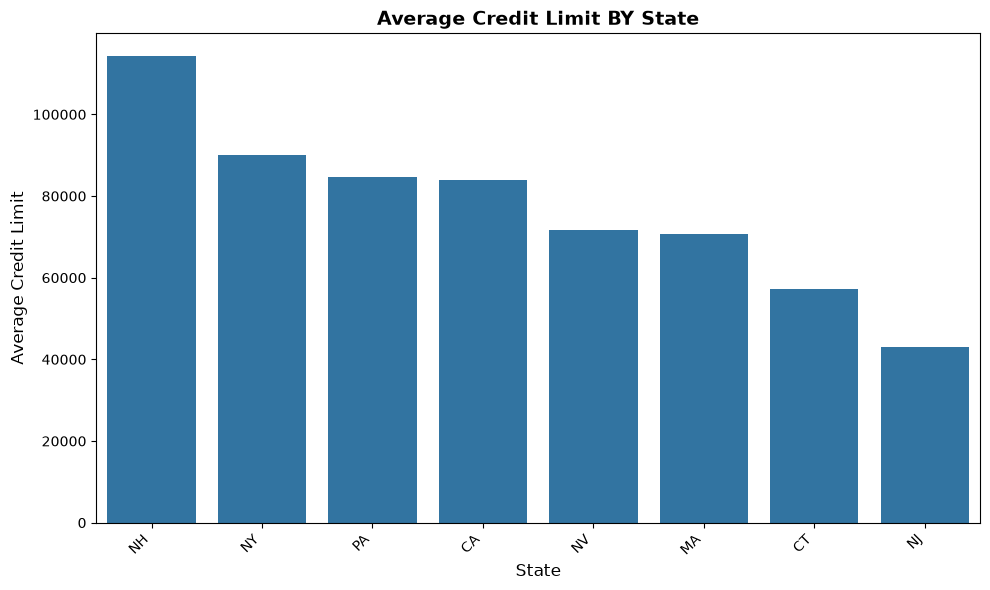

In [442]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
fig,ax =plt.subplots(figsize=(10,6))
sns.barplot(state_credit_limit,x="state",y="avg_credit_limit",ax=ax)
ax.set_xlabel("State",fontsize=12)
ax.set_ylabel("Average Credit Limit",fontsize=12)
ax.set_title("Average Credit Limit BY State",fontsize=14,fontweight="bold")
plt.xticks(rotation=45,ha="right"
           )
plt.tight_layout()
plt.show()


### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [443]:
# Replace None with your code
q=""" 
SELECT c.customerName,SUM(amount)as total_payment
FROM customers as c
INNER JOIN payments as p
USING(customerNumber)
GROUP BY customerNumber
ORDER BY total_payment DESC
LIMIT 10

"""
top_customers=pd.read_sql(q,conn)
top_customers

,customerName,total_payment
0,Euro+ Shopping Channel,715738.98
1,Mini Gifts Distributors Ltd.,584188.24
2,"Australian Collectors, Co.",180585.07
3,Muscle Machine Inc,177913.95
4,"Dragon Souveniers, Ltd.",156251.03
5,"Down Under Souveniers, Inc",154622.08
6,"AV Stores, Co.",148410.09
7,"Anna's Decorations, Ltd",137034.22
8,Corporate Gift Ideas Co.,132340.78
9,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

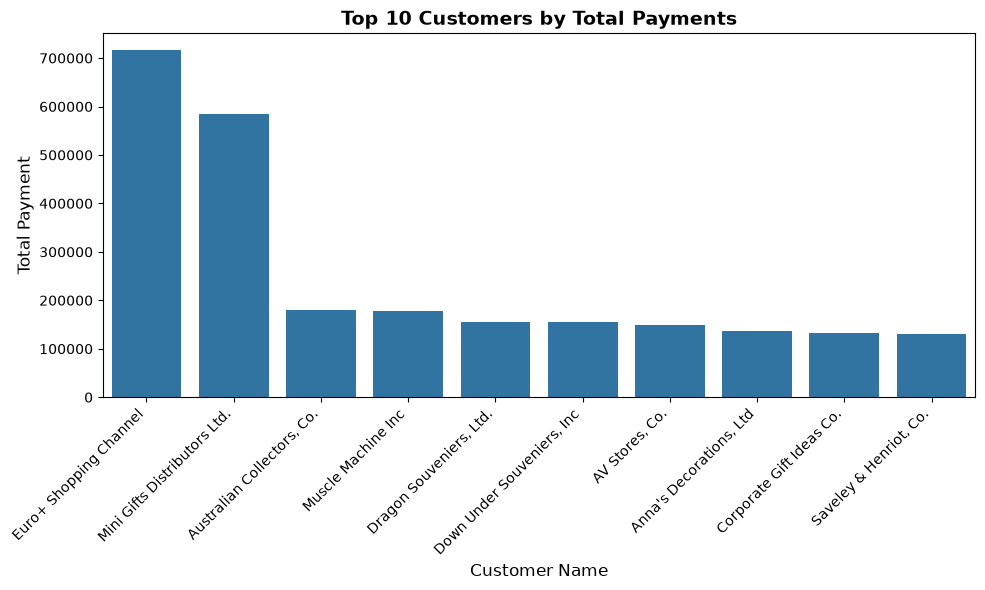

In [444]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
fig,ax =plt.subplots(figsize=(10,6))
sns.barplot(top_customers,x="customerName",y="total_payment",ax=ax)
ax.set_xlabel("Customer Name",fontsize=12)
ax.set_ylabel("Total Payment",fontsize=12)
ax.set_title("Top 10 Customers by Total Payments",fontsize=14,fontweight="bold")
plt.xticks(rotation=45,ha="right"
           )
plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [445]:
# Replace None with you code
q = """
SELECT c.customerNumber,
       c.customerName,
       od.productCode,
       p.productName,
       SUM(od.quantityOrdered) AS total_quantity,
       SUM(od.quantityOrdered * od.priceEach) AS total_amount
FROM customers c
JOIN orders o USING(customerNumber)
JOIN orderdetails od USING(orderNumber)
JOIN products p USING(productCode)
GROUP BY c.customerNumber, od.productCode
HAVING SUM(od.quantityOrdered) >= 10
ORDER BY total_amount ASC
"""
customer_product_quantities=pd.read_sql(q,conn)
customer_product_quantities



,customerNumber,customerName,productCode,productName,total_quantity,total_amount
0,382,Salzburg Collectables,S24_2972,1982 Lamborghini Diablo,15,481.50
1,282,Souveniers And Things Co.,S24_3969,1936 Mercedes Benz 500k Roadster,15,529.35
2,363,Online Diecast Creations Co.,S24_1937,1939 Chevrolet Deluxe Coupe,20,531.00
3,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11,553.52
4,350,Marseille Mini Autos,S24_1937,1939 Chevrolet Deluxe Coupe,20,557.60
...,...,...,...,...,...,...
2526,124,Mini Gifts Distributors Ltd.,S18_2238,1998 Chrysler Plymouth Prowler,123,18780.28
2527,141,Euro+ Shopping Channel,S24_3856,1956 Porsche 356A Coupe,161,21047.69
2528,124,Mini Gifts Distributors Ltd.,S12_3891,1969 Ford Falcon,137,21811.12
2529,124,Mini Gifts Distributors Ltd.,S12_1108,2001 Ferrari Enzo,140,24098.63


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [446]:
# Replace None with your code
q=""" 
SELECT p.productLine,SUM(od.quantityOrdered) as total_ordered_quantity,COUNT(DISTINCT p.productCode) as num_products
FROM products as P
LEFT JOIN orderdetails as od
USING(productCode)
GROUP BY p.productLine
"""

product_line=pd.read_sql(q,conn)
product_line

,productLine,total_ordered_quantity,num_products
0,Classic Cars,35582,38
1,Motorcycles,12778,13
2,Planes,11872,12
3,Ships,8532,9
4,Trains,2818,3
5,Trucks and Buses,11001,11
6,Vintage Cars,22933,24


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

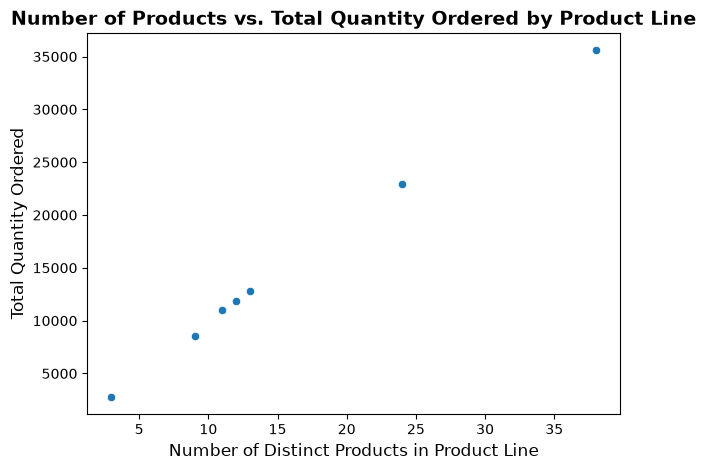

In [447]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig,ax=plt.subplots()
sns.scatterplot(data=product_line,x="num_products",y="total_ordered_quantity",ax=ax)
ax.set_xlabel("Number of Distinct Products in Product Line", fontsize=12)
ax.set_ylabel("Total Quantity Ordered", fontsize=12)
ax.set_title("Number of Products vs. Total Quantity Ordered by Product Line",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I used a **scatter plot** because I wanted to identify the relationship between two numerical variables: the number of products and the number of orders.

- **Finding:** The scatter plot shows a positive relationship between the number of products and the number of orders. As the number of products increases, the number of orders also tends to increase.
- **Why this chart makes sense:** A scatter plot makes it easy to see how two numerical variables relate to each other and whether they tend to increase or decrease together.


### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [448]:
# Replace None with your code
q= """ 
WITH smallOffices AS(
    SELECT officeCode,COUNT(employeeNumber) as total_employees
FROM employees e
INNER JOIN offices o
USING(officeCode)

GROUP BY officeCode
HAVING total_employees <5
)
SELECT 
    e.employeeNumber,
    e.firstName,
    e.lastName,
    e.email,
    e.officeCode,
    e.jobTitle,
    e.reportsTo
FROM employees as e
JOIN smallOffices as s
USING(officeCode)

"""

remote_office_employees=pd.read_sql(q,conn)
remote_office_employees

,employeeNumber,firstName,lastName,email,officeCode,jobTitle,reportsTo
0,1088,William,Patterson,wpatterson@classicmodelcars.com,6,Sales Manager (APAC),1056
1,1188,Julie,Firrelli,jfirrelli@classicmodelcars.com,2,Sales Rep,1143
2,1216,Steve,Patterson,spatterson@classicmodelcars.com,2,Sales Rep,1143
3,1286,Foon Yue,Tseng,ftseng@classicmodelcars.com,3,Sales Rep,1143
4,1323,George,Vanauf,gvanauf@classicmodelcars.com,3,Sales Rep,1143
5,1501,Larry,Bott,lbott@classicmodelcars.com,7,Sales Rep,1102
6,1504,Barry,Jones,bjones@classicmodelcars.com,7,Sales Rep,1102
7,1611,Andy,Fixter,afixter@classicmodelcars.com,6,Sales Rep,1088
8,1612,Peter,Marsh,pmarsh@classicmodelcars.com,6,Sales Rep,1088
9,1619,Tom,King,tking@classicmodelcars.com,6,Sales Rep,1088


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!
I created a CTE to calculate the total number of employees in each office and filter for offices with fewer than five employees. I then used an `INNER JOIN` to combine the results with the employee table using `officeCode`. This ensures that only matching records from both tables are returned.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [449]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [450]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [451]:
# read sql query result into pandas dataframe
def read_query(query,conn):
    df=pd.read_sql(query,conn)
    return df

In [452]:
q=""" 
SELECT *
FROM movie_basics
WHERE start_year >= 2010 AND start_year <= 2019
"""

movie_df =read_query(q,conn4)


In [453]:
# Display first 5 rows
movie_df.head()

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"


In [454]:
# display number of rows and columns
movie_df.shape

(145081, 6)

In [455]:
movie_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145081 entries, 0 to 145080
Data columns (total 6 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   movie_id         145081 non-null  str    
 1   primary_title    145081 non-null  str    
 2   original_title   145061 non-null  str    
 3   start_year       145081 non-null  int64  
 4   runtime_minutes  114316 non-null  float64
 5   genres           139722 non-null  str    
dtypes: float64(1), int64(1), str(4)
memory usage: 6.6 MB


In [456]:
# percentage of missing data
missing_percentage= (movie_df.isna().sum() / len(movie_df)) * 100
missing_percentage

movie_id            0.000000
primary_title       0.000000
original_title      0.013785
start_year          0.000000
runtime_minutes    21.205396
genres              3.693799
dtype: float64

In [457]:
## check for duplicates
movie_df.duplicated().sum()

np.int64(0)

In [458]:
q=""" 
SELECT *
FROM movie_ratings
"""
movie_rating=read_query(q,conn4)
movie_rating

,movie_id,averagerating,numvotes
0,tt10356526,8.3,31
1,tt10384606,8.9,559
2,tt1042974,6.4,20
3,tt1043726,4.2,50352
4,tt1060240,6.5,21
...,...,...,...
73851,tt9805820,8.1,25
73852,tt9844256,7.5,24
73853,tt9851050,4.7,14
73854,tt9886934,7.0,5


In [459]:
# general summary
movie_rating.info()

<class 'pandas.DataFrame'>
RangeIndex: 73856 entries, 0 to 73855
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   movie_id       73856 non-null  str    
 1   averagerating  73856 non-null  float64
 2   numvotes       73856 non-null  int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 1.7 MB


In [460]:
# check for duplicates
movie_rating["movie_id"].duplicated().sum()

np.int64(0)

In [461]:

q=""" 
SELECT *
FROM movie_akas
"""
movie_akas=read_query(q,conn4)
movie_akas

,movie_id,ordering,title,region,language,types,attributes,is_original_title
0,tt0369610,10,Джурасик свят,BG,bg,NaN,NaN,0.0
1,tt0369610,11,Jurashikku warudo,JP,NaN,imdbDisplay,NaN,0.0
2,tt0369610,12,Jurassic World: O Mundo dos Dinossauros,BR,NaN,imdbDisplay,NaN,0.0
3,tt0369610,13,O Mundo dos Dinossauros,BR,NaN,NaN,short title,0.0
4,tt0369610,14,Jurassic World,FR,NaN,imdbDisplay,NaN,0.0
...,...,...,...,...,...,...,...,...
331698,tt9827784,2,Sayonara kuchibiru,NaN,NaN,original,NaN,1.0
331699,tt9827784,3,Farewell Song,XWW,en,imdbDisplay,NaN,0.0
331700,tt9880178,1,La atención,NaN,NaN,original,NaN,1.0
331701,tt9880178,2,La atención,ES,NaN,NaN,NaN,0.0


In [462]:
principals=q=""" 
SELECT *
FROM principals
"""
principals=read_query(q,conn4)
principals

,movie_id,ordering,person_id,category,job,characters
0,tt0111414,1,nm0246005,actor,NaN,"[""The Man""]"
1,tt0111414,2,nm0398271,director,NaN,NaN
2,tt0111414,3,nm3739909,producer,producer,NaN
3,tt0323808,10,nm0059247,editor,NaN,NaN
4,tt0323808,1,nm3579312,actress,NaN,"[""Beth Boothby""]"
...,...,...,...,...,...,...
1028181,tt9692684,1,nm0186469,actor,NaN,"[""Ebenezer Scrooge""]"
1028182,tt9692684,2,nm4929530,self,NaN,"[""Herself"",""Regan""]"
1028183,tt9692684,3,nm10441594,director,NaN,NaN
1028184,tt9692684,4,nm6009913,writer,writer,NaN



### Cleaning Tasks

- In genre column one cell has more than one value
- **Missing values:** 
    - `attributes`:95% 
    - `language`:85% 
    - `job ` :80%
    - `characters` :60%
    - `types` :41% 
    - `region`         :16% 
    - `runtime_minutes` :21% 
    - `genres `          :3% 
  

- **Outliers:**
    - The `runtime_minutes` column contains extreme values, with a maximum of 51,420 minutes.
    - **Runtime percentiles:** The 0.05th percentile is 10 minutes and the 0.5th percentile is 41 minutes, while the 99.5th percentile is 175 minutes. Values outside the 0.05th-99.5th range (10-175 minutes) were treated as outliers and excluded from the runtime analysis.
- Standardization: inconsistent region and language codes.
 

### Visualization

In [463]:
def display_plot(plot_func,df,x,y,x_label,y_label,title,x_scale=None,y_scale=None,hue=None,**kwargs):
    fig,ax=plt.subplots(figsize=(10,6))
    plot_func(df,x=x,y=y,ax=ax,hue=hue)
    if x_scale:ax.set_xscale(x_scale)
    if y_scale:ax.set_yscale(y_scale)
    ax.set_xlabel(x_label,fontsize=12)
    ax.set_ylabel(y_label,fontsize=12)
    ax.set_title(title,fontsize=14,fontweight="bold")
    plt.tight_layout()
    plt.show()
    

#### Distribution of Average Price

In [464]:
movie_rating["averagerating"].describe()

count    73856.000000
mean         6.332729
std          1.474978
min          1.000000
25%          5.500000
50%          6.500000
75%          7.400000
max         10.000000
Name: averagerating, dtype: float64

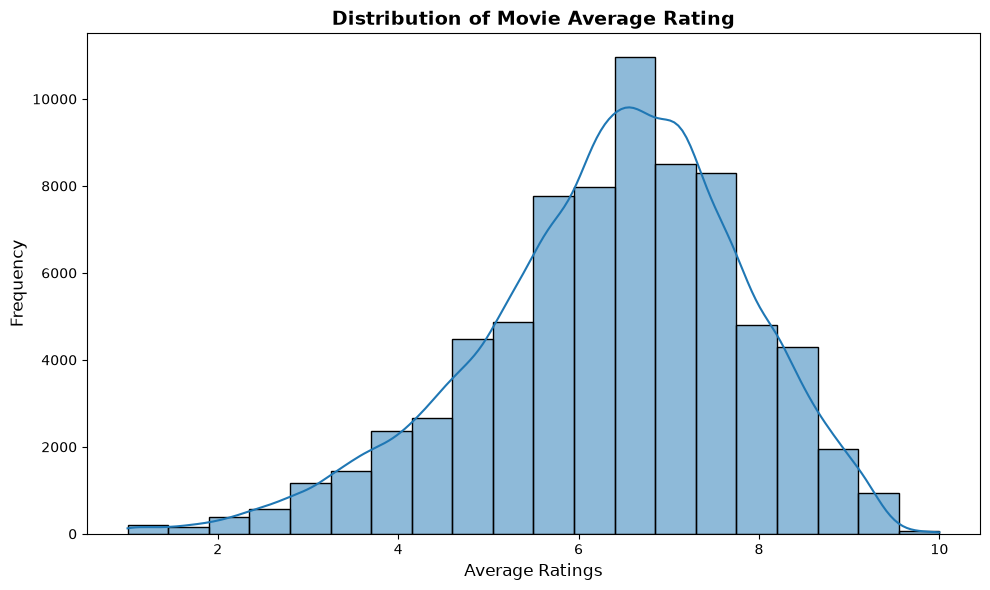

In [465]:
fig,ax=plt.subplots(figsize=(10,6))
sns.histplot(movie_rating,x="averagerating",bins=20,kde=True)
ax.set_xlabel("Average Ratings",fontsize=12)
ax.set_ylabel("Frequency",fontsize=12)
ax.set_title("Distribution of Movie Average Rating",fontsize=14,fontweight="bold")
plt.tight_layout()
plt.show()

**Observation**
- Average rating is slightly Left skewed with mean of 6.3 and median of 6.5


#### Is there a relationship between average rating and numvotes

In [466]:
movie_rating["numvotes"].value_counts()

numvotes
6        2875
5        2699
7        2476
8        2167
9        1929
         ... 
22399       1
5947        1
9988        1
5863        1
4057        1
Name: count, Length: 7349, dtype: int64

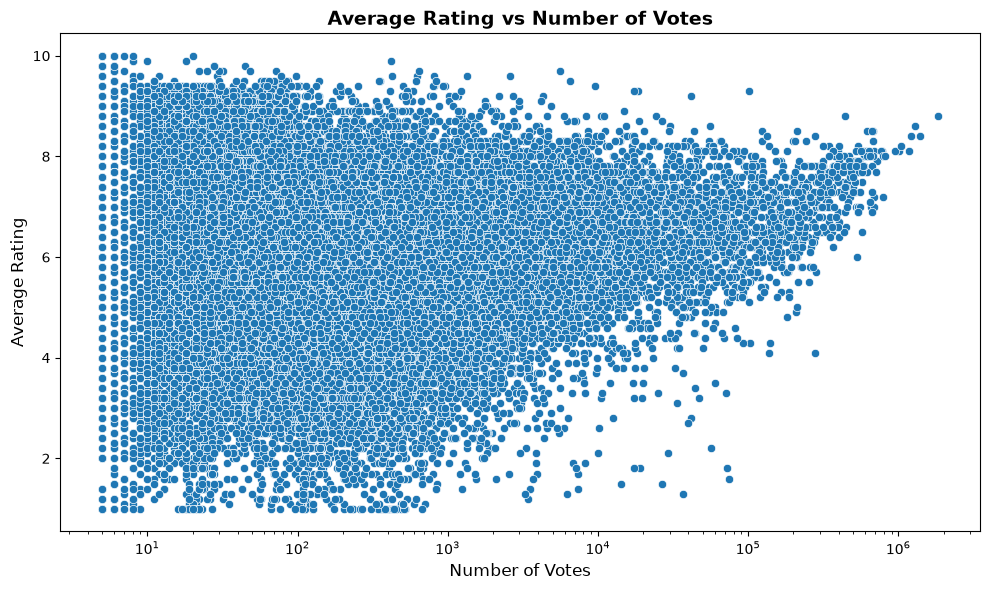

In [467]:
# visualize relationship between average rating and number of votes
display_plot(sns.scatterplot,movie_rating,x="numvotes",y="averagerating",x_scale="log",x_label="Number of Votes",y_label="Average Rating",title="Average Rating vs Number of Votes")

**Observation**
- Movies with few votes have ratings scattered across the whole 1 to 10 range, while movies with many votes have ratings that cluster in a narrow band, mostly between about 5 and 9.

## is there any relationship between principal category and rating

In [468]:
q=""" 
SELECT *
FROM movie_ratings
JOIN principals
USING(movie_id)
"""
movie_rating_principal=read_query(q,conn4)
movie_rating_principal

,movie_id,averagerating,numvotes,ordering,person_id,category,job,characters
0,tt10356526,8.3,31,1,nm4718369,actor,NaN,"[""Sukh""]"
1,tt10356526,8.3,31,2,nm10007357,actress,NaN,"[""Raunak""]"
2,tt10356526,8.3,31,3,nm8743259,actress,NaN,"[""Jaanpreet""]"
3,tt10356526,8.3,31,4,nm3760302,actor,NaN,"[""Garry Randhawa""]"
4,tt10356526,8.3,31,5,nm8353804,director,NaN,NaN
...,...,...,...,...,...,...,...,...
629750,tt9894098,6.3,128,6,nm7120982,producer,producer,NaN
629751,tt9894098,6.3,128,7,nm10166058,composer,NaN,NaN
629752,tt9894098,6.3,128,8,nm2518188,cinematographer,NaN,NaN
629753,tt9894098,6.3,128,9,nm5481676,editor,NaN,NaN


In [469]:
movie_rating_principal.info()

<class 'pandas.DataFrame'>
RangeIndex: 629755 entries, 0 to 629754
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   movie_id       629755 non-null  str    
 1   averagerating  629755 non-null  float64
 2   numvotes       629755 non-null  int64  
 3   ordering       629755 non-null  int64  
 4   person_id      629755 non-null  str    
 5   category       629755 non-null  str    
 6   job            124945 non-null  str    
 7   characters     248129 non-null  str    
dtypes: float64(1), int64(2), str(5)
memory usage: 38.4 MB


In [470]:
## percentage of missing values
movie_rating_principal.isna().sum()*100/len(movie_rating_principal)

movie_id          0.000000
averagerating     0.000000
numvotes          0.000000
ordering          0.000000
person_id         0.000000
category          0.000000
job              80.159745
characters       60.599122
dtype: float64

In [471]:
movie_rating_principal["category"].value_counts()

category
actor                  155567
actress                 92875
producer                80367
director                77452
writer                  52412
composer                49898
cinematographer         46652
self                    32921
editor                  32428
production_designer      7038
archive_footage          2133
archive_sound              12
Name: count, dtype: int64

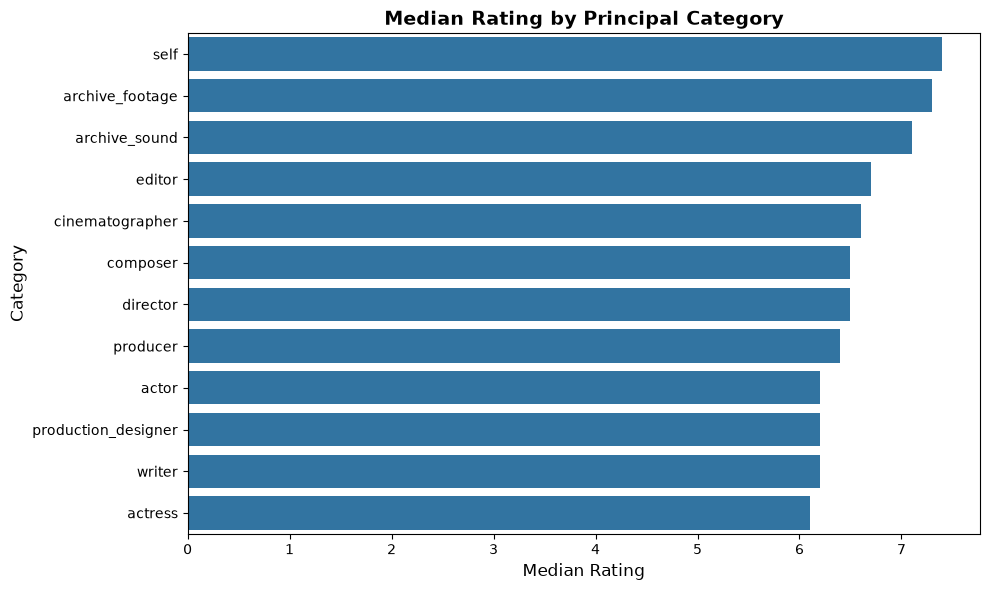

In [472]:
category_rating=movie_rating_principal.groupby("category")["averagerating"].median().sort_values(ascending=False).reset_index()


display_plot(sns.barplot,category_rating,y="category",x="averagerating",y_label="Category",x_label="Median Rating",title="Median Rating by Principal Category")

**Observation**
- Top three principal Category
  1.  self : 7.4
  2. archive_footage :7.3
  3. archive_sound :7.1
- Bottom three
  1. actress : 6.1
  2. writer 6.2
  3. production_designer 6.2

#### Is there a relationship between Average rating and run time

In [473]:
q=""" 
SELECT *
FROM movie_basics
JOIN movie_ratings
USING(movie_id)
"""
movie_basics_rating=read_query(q,conn4)
movie_basics_rating

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama",7.0,77
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama",7.2,43
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama,6.9,4517
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama",6.1,13
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy",6.5,119
...,...,...,...,...,...,...,...,...
73851,tt9913084,Diabolik sono io,Diabolik sono io,2019,75.0,Documentary,6.2,6
73852,tt9914286,Sokagin Çocuklari,Sokagin Çocuklari,2019,98.0,"Drama,Family",8.7,136
73853,tt9914642,Albatross,Albatross,2017,NaN,Documentary,8.5,8
73854,tt9914942,La vida sense la Sara Amat,La vida sense la Sara Amat,2019,NaN,NaN,6.6,5


In [474]:
# runtime  at different percentiles
quantiles =np.array([0.0005,0.005,0.01,0.02,0.03,0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95,0.99,0.995,1])
movie_basics_rating["runtime_minutes"].quantile(quantiles)

0.0005       10.0
0.0050       41.0
0.0100       45.0
0.0200       50.0
0.0300       52.0
0.0500       58.0
0.1000       69.0
0.2000       78.0
0.3000       84.0
0.4000       88.0
0.5000       91.0
0.6000       95.0
0.7000      100.0
0.8000      108.0
0.9000      120.0
0.9500      135.0
0.9900      161.0
0.9950      175.0
1.0000    51420.0
Name: runtime_minutes, dtype: float64

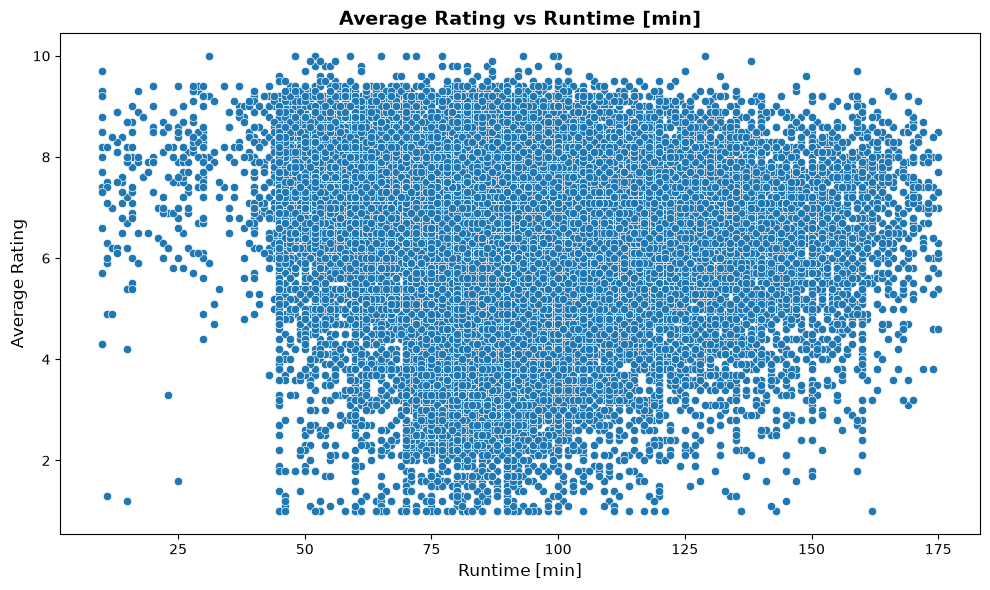

In [475]:
lower=movie_basics_rating["runtime_minutes"].quantile(0.0005)
upper =movie_basics_rating["runtime_minutes"].quantile(0.995)
filtered=movie_basics_rating[movie_basics_rating["runtime_minutes"].between(lower,upper)]

display_plot(sns.scatterplot,filtered,x="runtime_minutes",y="averagerating",
             x_label="Runtime [min]",y_label="Average Rating",title="Average Rating vs Runtime [min]",x_scale='linear',y_scale='linear')

**Decision**
- Runtime was restricted to the 0.05 to 99.5th percentile (10 to 175 minutes) to remove extreme outliers (up to 51,420 minutes) that compressed the plot.
  
**Observation**
- Movies under ~45 minutes are few, and are mostly rated 6 or higher.
- Between ~45 and 125 minutes, ratings cover almost the full range (1 to 10), so runtime alone does not explain rating.
- Above ~125 minutes, very low ratings become rarer and ratings concentrate between about 4 and 9, suggesting a slight upward shift.
- Overall, there is no strong linear relationship between runtime and rating.


#### Is the a relationship between genres and average rating

In [476]:
# create a copy
genre_df=movie_basics_rating.copy()

# one row per movie per genre
genre_df["genres"]=genre_df["genres"].str.split(",")
genre_df=genre_df.explode("genres")

#check for duplicates
genre_df.duplicated().sum()

genre_df =genre_df.reset_index(drop=True)
genre_df

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,Action,7.0,77
1,tt0063540,Sunghursh,Sunghursh,2013,175.0,Crime,7.0,77
2,tt0063540,Sunghursh,Sunghursh,2013,175.0,Drama,7.0,77
3,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,Biography,7.2,43
4,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,Drama,7.2,43
...,...,...,...,...,...,...,...,...
129289,tt9914286,Sokagin Çocuklari,Sokagin Çocuklari,2019,98.0,Drama,8.7,136
129290,tt9914286,Sokagin Çocuklari,Sokagin Çocuklari,2019,98.0,Family,8.7,136
129291,tt9914642,Albatross,Albatross,2017,NaN,Documentary,8.5,8
129292,tt9914942,La vida sense la Sara Amat,La vida sense la Sara Amat,2019,NaN,NaN,6.6,5


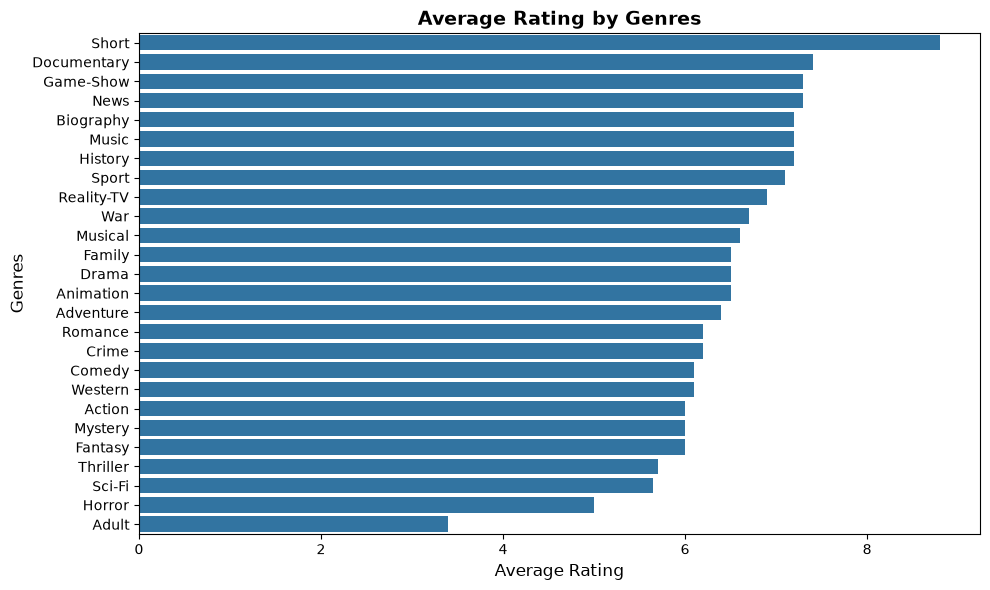

In [477]:
# group by genres and get median averageRating
genre_rating=(genre_df.groupby("genres")["averagerating"].median().sort_values(ascending=False)).reset_index()

display_plot(sns.barplot,genre_rating,y="genres",x="averagerating",x_label="Average Rating",y_label="Genres",title="Average Rating by Genres")



**Observation**
- Top three genres based on rating
- 1. short :8.8
- 2. Documentary:7.4
- 3. Game_show 7.3
- 3. news 7.3
- Bottom 3 based on rating
- 1. Adult :3.4
- 2. Horror:5.0
- 3. sci-fi :5.65

In [478]:
genre_rating

,genres,averagerating
0,Short,8.80
1,Documentary,7.40
2,Game-Show,7.30
3,News,7.30
4,Biography,7.20
5,Music,7.20
6,History,7.20
7,Sport,7.10
8,Reality-TV,6.90
9,War,6.70


#### Is movie rating affected by if it original or not

In [479]:
q=""" 
SELECT *
FROM movie_ratings
JOIN movie_akas
USING(movie_id)
"""
movie_rating_akas=read_query(q,conn4)
movie_rating_akas

,movie_id,averagerating,numvotes,ordering,title,region,language,types,attributes,is_original_title
0,tt1042974,6.4,20,1,Just Inès,NaN,NaN,original,NaN,1.0
1,tt1042974,6.4,20,2,Samo Ines,RS,NaN,imdbDisplay,NaN,0.0
2,tt1042974,6.4,20,3,Just Inès,GB,NaN,NaN,NaN,0.0
3,tt1043726,4.2,50352,1,Legenda lui Hercule,RO,NaN,working,NaN,0.0
4,tt1043726,4.2,50352,2,La légende d'Hercule,FR,NaN,imdbDisplay,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...
261801,tt9691896,6.3,21,4,Coming Out,NaN,NaN,original,NaN,1.0
261802,tt9844256,7.5,24,1,Code Geass: Lelouch of the Rebellion Episode III,JP,NaN,NaN,NaN,0.0
261803,tt9844256,7.5,24,2,Code Geass: Lelouch of the Rebellion Episode III,NaN,NaN,original,NaN,1.0
261804,tt9844256,7.5,24,3,Code Geass: Lelouch of the Rebellion - Glorifi...,XWW,en,imdbDisplay,NaN,0.0


In [480]:
movie_akas.info()

<class 'pandas.DataFrame'>
RangeIndex: 331703 entries, 0 to 331702
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   movie_id           331703 non-null  str    
 1   ordering           331703 non-null  int64  
 2   title              331703 non-null  str    
 3   region             278410 non-null  str    
 4   language           41715 non-null   str    
 5   types              168447 non-null  str    
 6   attributes         14925 non-null   str    
 7   is_original_title  331678 non-null  float64
dtypes: float64(1), int64(1), str(6)
memory usage: 20.2 MB


In [481]:
# check for duplicates
movie_akas.duplicated().sum()

np.int64(0)

In [482]:
# percentage of missing values
(movie_rating_akas.isna().sum()*100/len(movie_rating_akas)).sort_values(ascending=False)

attributes           95.063520
language             85.836841
types                41.457415
region               16.601988
movie_id              0.000000
averagerating         0.000000
numvotes              0.000000
ordering              0.000000
title                 0.000000
is_original_title     0.000000
dtype: float64

In [483]:
# original vs not original
movie_rating_akas["is_original_title"].value_counts()

is_original_title
0.0    224911
1.0     36895
Name: count, dtype: int64

  is_original_title  averagerating
0      Not Original            6.4
1          Original            6.3


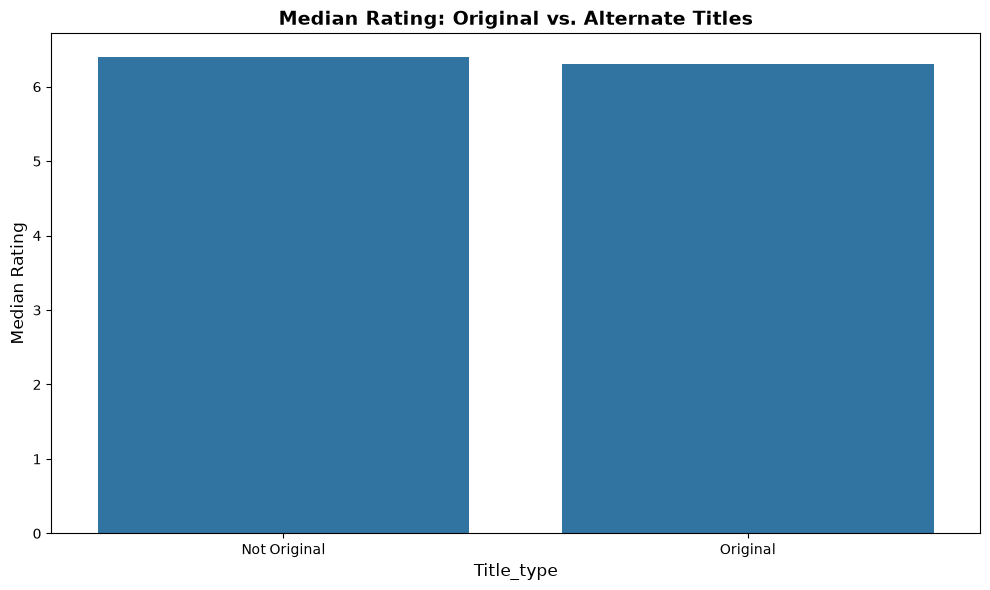

In [484]:
# median
median=(movie_rating_akas.groupby("is_original_title")["averagerating"].median().reset_index())
median["is_original_title"]=median["is_original_title"].map({0.0:"Not Original",1:"Original"})
print(median)

display_plot(sns.barplot,median,x="is_original_title",y="averagerating",
             x_label="Title_type",y_label="Median Rating",title="Median Rating: Original vs. Alternate Titles")

**Observatiom**
- Whether movie is original or not does not affect rating

## Business Question
Among movies released 2010-2019 with at least 100 votes, which genres earn the highest median audience rating, and does runtime change that?

In [485]:
genre_df.head()

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres,averagerating,numvotes
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,Action,7.0,77
1,tt0063540,Sunghursh,Sunghursh,2013,175.0,Crime,7.0,77
2,tt0063540,Sunghursh,Sunghursh,2013,175.0,Drama,7.0,77
3,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,Biography,7.2,43
4,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,Drama,7.2,43


In [486]:
filtered_genres=genre_df[genre_df["numvotes"]>= 100]
filtered_genres=filtered_genres[filtered_genres["runtime_minutes"].between(lower,upper)]

In [487]:
genre_summary =filtered_genres.groupby("genres").agg(
    median_rating=("averagerating","median"),
    total_votes=("numvotes","sum")
).reset_index().sort_values(by="median_rating",ascending=False)



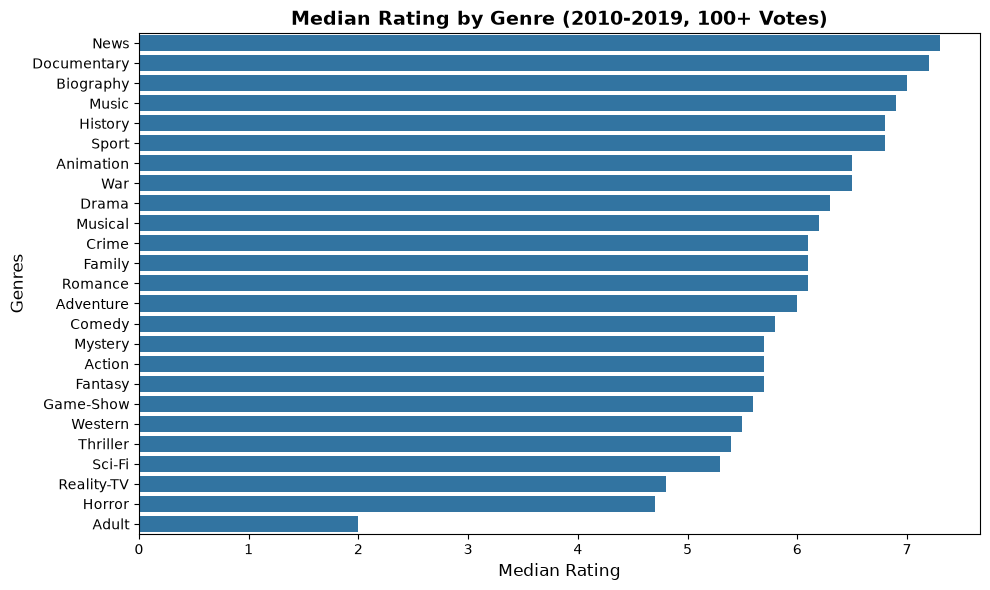

In [488]:
display_plot(sns.barplot,genre_summary,y="genres",x="median_rating",x_label="Median Rating",y_label="Genres",title="Median Rating by Genre (2010-2019, 100+ Votes)",)

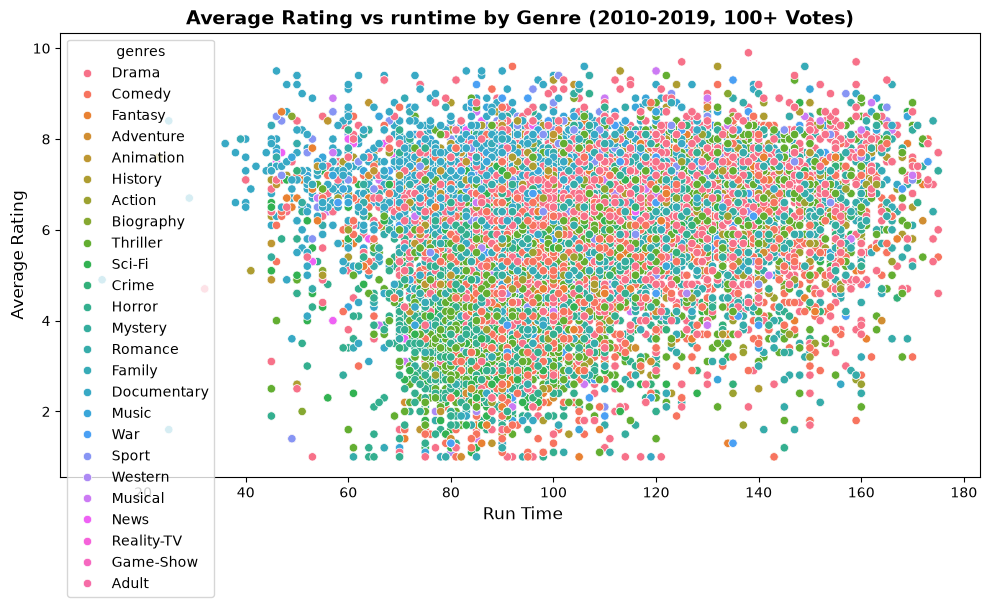

In [489]:
display_plot(sns.scatterplot,filtered_genres,x="runtime_minutes",y="averagerating",
x_label=" Run Time",y_label="Average Rating",title="Average Rating vs runtime by Genre (2010-2019, 100+ Votes)",hue="genres")


## Conclusion

**Question:** Among movies released 2010-2019 with at least 100 votes, which genres earn the highest median audience rating, and does runtime change that?

**Answer:**
- **Top 3 genres:** News (~7.3), Documentary (~7.2), Biography (~7.0). Music, History and Sport follow closely at about 6.8-6.9.
- **Bottom 3 genres:** Adult (~2.0), Horror (~4.7), Reality-TV (~4.8).
- **Pattern:** Non-fiction and fact-based genres (News, Documentary, Biography, History, Sport) rate highest. Genre-driven fiction such as Thriller, Sci-Fi and Horror rates lower, with medians around 4.7-5.4. Drama sits in the middle at about 6.3.
- Runtime does not affect genre ratings

**Limitations:**
- Movies without runtime data and runtime outliers were excluded; ratings exist for only about half of all movies.



